In [1]:
import os
import re
import zipfile
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
from sklearn.preprocessing import LabelEncoder

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
pd.set_option("display.max_colwidth", 120)

print("Libraries imported successfully.")

Libraries imported successfully.


In [8]:
import zipfile
import pandas as pd

ZIP_PATH = "/content/archive (1).zip"

expected_categories = {
    "business",
    "entertainment",
    "politics",
    "sport",
    "tech"
}

records = {}

with zipfile.ZipFile(ZIP_PATH, "r") as z:

    for name in z.namelist():

        if not name.lower().endswith(".txt"):
            continue

        parts = name.strip("/").split("/")

        if len(parts) < 2:
            continue

        category = parts[-2].lower()

        if category not in expected_categories:
            continue

        filename = parts[-1]
        key = (category, filename)

        if key not in records:
            records[key] = name

    data = []

    for (category, filename), path in records.items():

        with z.open(path) as file:
            article = file.read().decode(
                "latin-1"
            ).strip()

        if article:
            data.append({
                "text": article,
                "category": category
            })

df = pd.DataFrame(data)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nCategory distribution:")
print(df["category"].value_counts())

print("\nSample articles:")
display(df.head())

Dataset loaded successfully!
Dataset shape: (2225, 2)

Category distribution:
category
sport            511
business         510
politics         417
tech             401
entertainment    386
Name: count, dtype: int64

Sample articles:


,text,category
0,Ad sales boost Time Warner profit\n\nQuarterly profits at US media giant TimeWarner jumped 76% to $1.13bn (Â£600m) f...,business
1,Dollar gains on Greenspan speech\n\nThe dollar has hit its highest level against the euro in almost three months aft...,business
2,Yukos unit buyer faces loan claim\n\nThe owners of embattled Russian oil giant Yukos are to ask the buyer of its for...,business
3,High fuel prices hit BA's profits\n\nBritish Airways has blamed high fuel prices for a 40% drop in profits.\n\nRepor...,business
4,Pernod takeover talk lifts Domecq\n\nShares in UK drinks and food firm Allied Domecq have risen on speculation that ...,business


In [9]:
# Dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Column information
print("\nDataset information:")
df.info()

# Missing values
print("\nMissing values:")
print(df.isnull().sum())

# Duplicate articles
print("\nDuplicate articles:", df.duplicated(subset=["text"]).sum())

Number of rows: 2225
Number of columns: 2

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2225 entries, 0 to 2224
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   text      2225 non-null   object
 1   category  2225 non-null   object
dtypes: object(2)
memory usage: 34.9+ KB

Missing values:
text        0
category    0
dtype: int64

Duplicate articles: 98


In [10]:
# Remove missing values
df = df.dropna(subset=["text", "category"])

# Remove empty articles
df["text"] = df["text"].astype(str).str.strip()
df = df[df["text"] != ""]

# Remove duplicate articles
df = df.drop_duplicates(subset=["text"])

# Reset index
df = df.reset_index(drop=True)

print("Dataset after cleaning:", df.shape)
print("\nCategory distribution:")
print(df["category"].value_counts())

Dataset after cleaning: (2127, 2)

Category distribution:
category
sport            505
business         503
politics         403
entertainment    369
tech             347
Name: count, dtype: int64


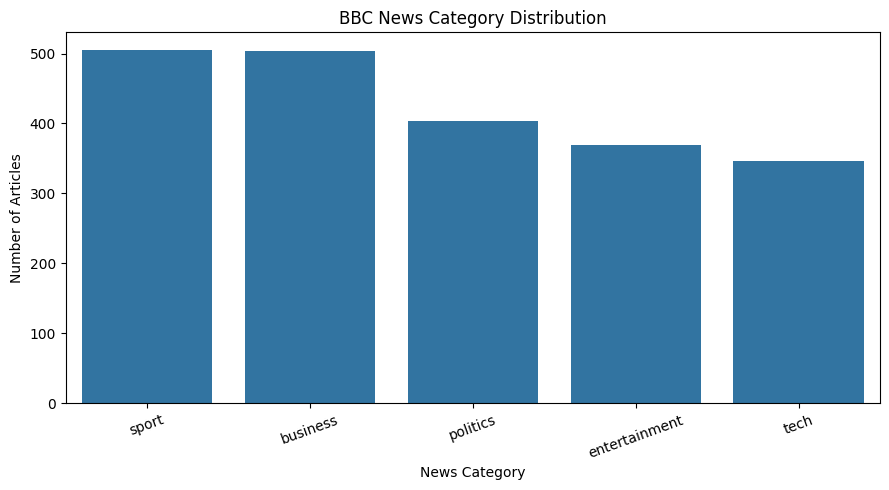

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="category",
    order=df["category"].value_counts().index
)

plt.title("BBC News Category Distribution")
plt.xlabel("News Category")
plt.ylabel("Number of Articles")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [12]:
for category in sorted(df["category"].unique()):

    print("\nCATEGORY:", category.upper())

    article = df[df["category"] == category]["text"].iloc[0]

    print(article[:500])
    print("-" * 70)


CATEGORY: BUSINESS
Ad sales boost Time Warner profit

Quarterly profits at US media giant TimeWarner jumped 76% to $1.13bn (Â£600m) for the three months to December, from $639m year-earlier.

The firm, which is now one of the biggest investors in Google, benefited from sales of high-speed internet connections and higher advert sales. TimeWarner said fourth quarter sales rose 2% to $11.1bn from $10.9bn. Its profits were buoyed by one-off gains which offset a profit dip at Warner Bros, and less users for AOL.

Time 
----------------------------------------------------------------------

CATEGORY: ENTERTAINMENT
Gallery unveils interactive tree

A Christmas tree that can receive text messages has been unveiled at London's Tate Britain art gallery.

The spruce has an antenna which can receive Bluetooth texts sent by visitors to the Tate. The messages will be "unwrapped" by sculptor Richard Wentworth, who is responsible for decorating the tree with broken plates and light bulbs. It is the 1

In [13]:
import nltk

nltk.download("stopwords")
nltk.download("punkt")
nltk.download("punkt_tab")

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize
import string

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


In [14]:
stop_words = set(stopwords.words("english"))
stemmer = PorterStemmer()

def preprocess_text(text):

    # Convert to lowercase
    text = text.lower()

    # Tokenization
    tokens = word_tokenize(text)

    # Remove punctuation and stopwords
    tokens = [
        word for word in tokens
        if word.isalpha()
        and word not in stop_words
    ]

    # Stemming
    tokens = [
        stemmer.stem(word)
        for word in tokens
    ]

    return " ".join(tokens)

In [15]:
df["processed_text"] = df["text"].apply(preprocess_text)

print("Original text:")
print(df["text"].iloc[0][:500])

print("\nProcessed text:")
print(df["processed_text"].iloc[0][:500])

Original text:
Ad sales boost Time Warner profit

Quarterly profits at US media giant TimeWarner jumped 76% to $1.13bn (Â£600m) for the three months to December, from $639m year-earlier.

The firm, which is now one of the biggest investors in Google, benefited from sales of high-speed internet connections and higher advert sales. TimeWarner said fourth quarter sales rose 2% to $11.1bn from $10.9bn. Its profits were buoyed by one-off gains which offset a profit dip at Warner Bros, and less users for AOL.

Time 

Processed text:
ad sale boost time warner profit quarterli profit us media giant timewarn jump three month decemb firm one biggest investor googl benefit sale internet connect higher advert sale timewarn said fourth quarter sale rose profit buoy gain offset profit dip warner bro less user aol time warner said friday own googl internet busi aol mix fortun lost subscrib fourth quarter profit lower preced three quarter howev compani said aol underli profit except item rose back str

In [16]:
print("Dataset shape:", df.shape)

print("\nOriginal article:")
print(df["text"].iloc[0][:300])

print("\nProcessed article:")
print(df["processed_text"].iloc[0][:300])

print("\nEmpty processed documents:",
      (df["processed_text"].str.strip() == "").sum())

Dataset shape: (2127, 3)

Original article:
Ad sales boost Time Warner profit

Quarterly profits at US media giant TimeWarner jumped 76% to $1.13bn (Â£600m) for the three months to December, from $639m year-earlier.

The firm, which is now one of the biggest investors in Google, benefited from sales of high-speed internet connections and high

Processed article:
ad sale boost time warner profit quarterli profit us media giant timewarn jump three month decemb firm one biggest investor googl benefit sale internet connect higher advert sale timewarn said fourth quarter sale rose profit buoy gain offset profit dip warner bro less user aol time warner said frida

Empty processed documents: 0


In [17]:
from sklearn.model_selection import train_test_split

X = df["processed_text"]
y = df["category"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 1701
Testing samples: 426


In [18]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2
)

X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)
print("Total features:", len(tfidf.get_feature_names_out()))

Training TF-IDF shape: (1701, 10000)
Testing TF-IDF shape: (426, 10000)
Total features: 10000


In [19]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

models = {
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        metric="cosine",
        algorithm="brute"
    ),

    "SVM": LinearSVC(
        random_state=42
    ),

    "Naive Bayes": MultinomialNB()
}

In [20]:
for name, model in models.items():

    print("Training:", name)

    model.fit(
        X_train_tfidf,
        y_train
    )

print("\nAll four models trained successfully!")

Training: Decision Tree
Training: KNN
Training: SVM
Training: Naive Bayes

All four models trained successfully!


In [21]:
for name, model in models.items():

    print("Training:", name)

    model.fit(
        X_train_tfidf,
        y_train
    )

print("\nAll four models trained successfully!")

Training: Decision Tree
Training: KNN
Training: SVM
Training: Naive Bayes

All four models trained successfully!


In [22]:
predictions = {}

for name, model in models.items():

    predictions[name] = model.predict(
        X_test_tfidf
    )

print("Predictions completed!")

Predictions completed!


In [23]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = []

for name, y_pred in predictions.items():

    results.append({
        "Model": name,

        "Accuracy": accuracy_score(
            y_test, y_pred
        ),

        "Precision": precision_score(
            y_test, y_pred,
            average="weighted"
        ),

        "Recall": recall_score(
            y_test, y_pred,
            average="weighted"
        ),

        "F1 Score": f1_score(
            y_test, y_pred,
            average="weighted"
        )
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Decision Tree,0.8216,0.8241,0.8216,0.8221
1,KNN,0.9531,0.9534,0.9531,0.9529
2,SVM,0.9789,0.9790,0.9789,0.9789
3,Naive Bayes,0.9789,0.9793,0.9789,0.9789


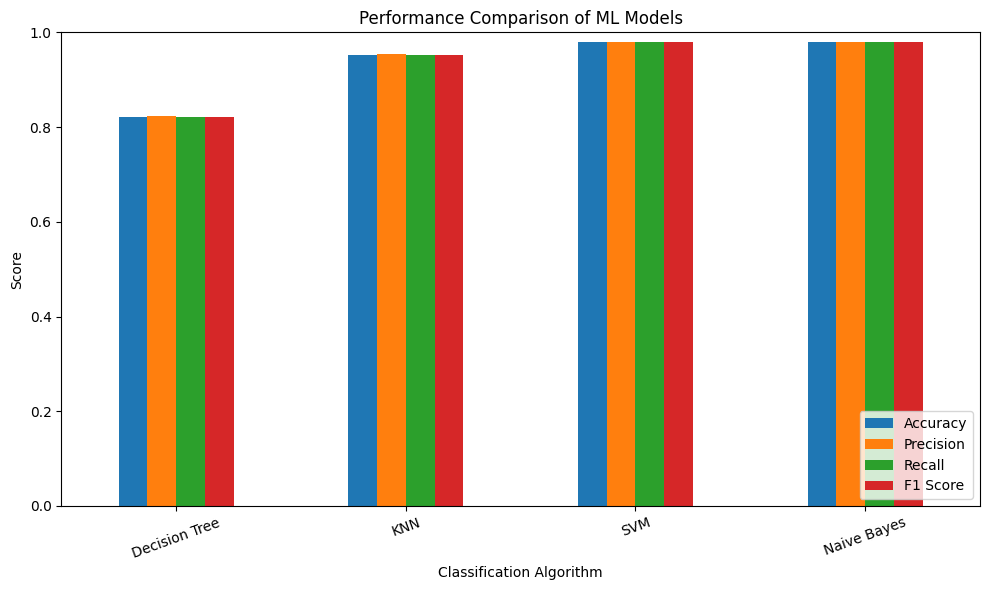

In [24]:
results_df.set_index("Model").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Performance Comparison of ML Models")
plt.ylabel("Score")
plt.xlabel("Classification Algorithm")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

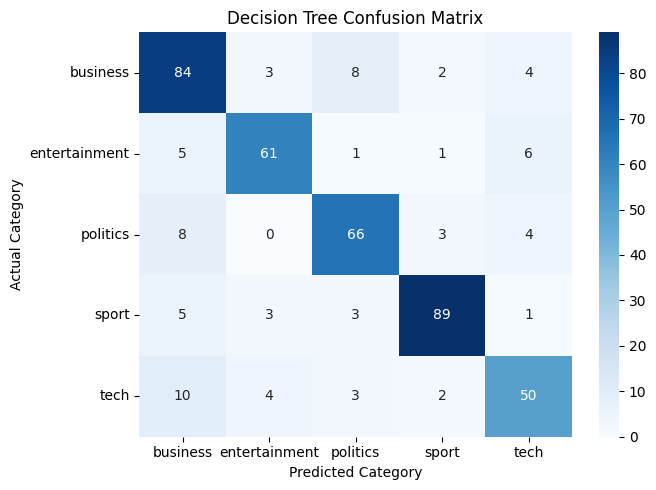

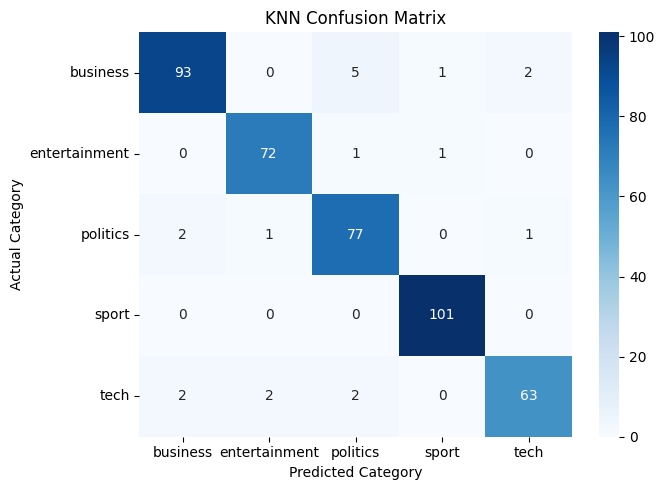

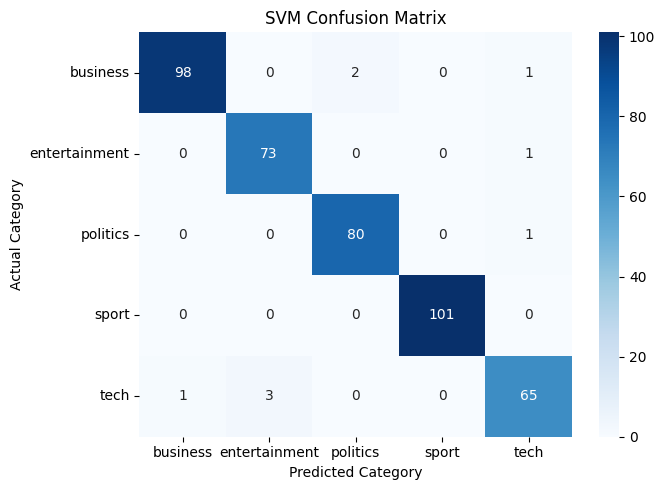

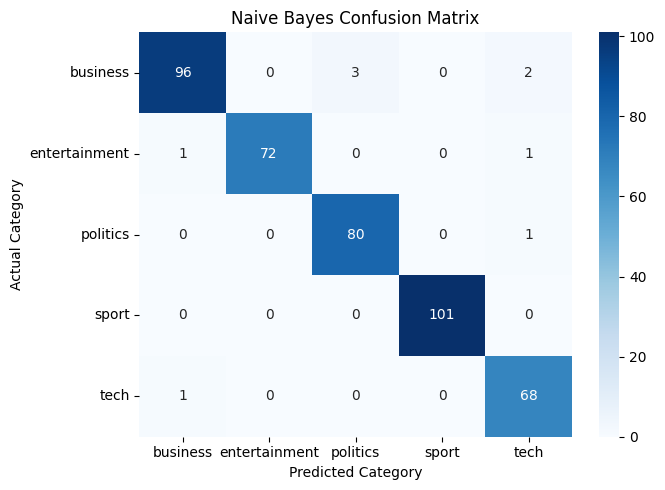

In [25]:
from sklearn.metrics import confusion_matrix

for name, y_pred in predictions.items():

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=sorted(y.unique())
    )

    plt.figure(figsize=(7, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=sorted(y.unique()),
        yticklabels=sorted(y.unique())
    )

    plt.title(name + " Confusion Matrix")
    plt.xlabel("Predicted Category")
    plt.ylabel("Actual Category")

    plt.tight_layout()
    plt.show()

In [26]:
knn_results = []

for k in [3, 5, 7]:

    knn = KNeighborsClassifier(
        n_neighbors=k,
        metric="cosine",
        algorithm="brute"
    )

    knn.fit(X_train_tfidf, y_train)

    pred = knn.predict(X_test_tfidf)

    knn_results.append({
        "K Value": k,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(
            y_test, pred, average="weighted"
        ),
        "Recall": recall_score(
            y_test, pred, average="weighted"
        ),
        "F1 Score": f1_score(
            y_test, pred, average="weighted"
        )
    })

knn_results_df = pd.DataFrame(knn_results)

display(knn_results_df.round(4))

,K Value,Accuracy,Precision,Recall,F1 Score
0,3,0.9319,0.9318,0.9319,0.9318
1,5,0.9531,0.9534,0.9531,0.9529
2,7,0.9601,0.9607,0.9601,0.9600


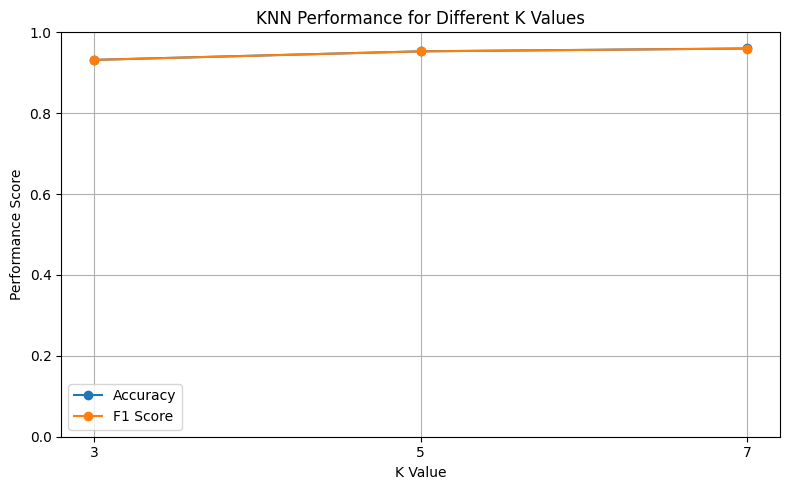

In [27]:
knn_results_df.set_index("K Value")[
    ["Accuracy", "F1 Score"]
].plot(
    marker="o",
    figsize=(8, 5)
)

plt.title("KNN Performance for Different K Values")
plt.xlabel("K Value")
plt.ylabel("Performance Score")
plt.xticks([3, 5, 7])
plt.ylim(0, 1)
plt.grid(True)
plt.tight_layout()
plt.show()

In [28]:
best_model = results_df.loc[
    results_df["F1 Score"].idxmax()
]

print("BEST PERFORMING MODEL")
print("---------------------")

print("Model:", best_model["Model"])
print("Accuracy:", round(best_model["Accuracy"], 4))
print("Precision:", round(best_model["Precision"], 4))
print("Recall:", round(best_model["Recall"], 4))
print("F1 Score:", round(best_model["F1 Score"], 4))

BEST PERFORMING MODEL
---------------------
Model: Naive Bayes
Accuracy: 0.9789
Precision: 0.9793
Recall: 0.9789
F1 Score: 0.9789


In [29]:
import os

os.makedirs("results", exist_ok=True)

results_df.to_csv(
    "results/model_comparison.csv",
    index=False
)

knn_results_df.to_csv(
    "results/knn_what_if_results.csv",
    index=False
)

print("Results saved successfully!")

Results saved successfully!


In [30]:
from sklearn.metrics import precision_score, recall_score, f1_score

advanced_results = []

for name, y_pred in predictions.items():

    advanced_results.append({
        "Model": name,
        "Macro Precision": precision_score(
            y_test, y_pred, average="macro"
        ),
        "Macro Recall": recall_score(
            y_test, y_pred, average="macro"
        ),
        "Macro F1": f1_score(
            y_test, y_pred, average="macro"
        ),
        "Weighted F1": f1_score(
            y_test, y_pred, average="weighted"
        )
    })

advanced_df = pd.DataFrame(advanced_results)

display(advanced_df.round(6))

,Model,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,Decision Tree,0.822145,0.815330,0.818037,0.822100
1,KNN,0.951955,0.951485,0.951415,0.952934
2,SVM,0.976383,0.977293,0.976767,0.978851
3,Naive Bayes,0.977578,0.979326,0.978255,0.978899


In [31]:
for name in ["SVM", "Naive Bayes"]:

    print("\n", name)

    pred = predictions[name]

    print("Accuracy:",
          accuracy_score(y_test, pred))

    print("Precision:",
          precision_score(
              y_test, pred, average="weighted"
          ))

    print("Recall:",
          recall_score(
              y_test, pred, average="weighted"
          ))

    print("F1-score:",
          f1_score(
              y_test, pred, average="weighted"
          ))


 SVM
Accuracy: 0.9788732394366197
Precision: 0.9789648308569544
Recall: 0.9788732394366197
F1-score: 0.9788505203647861

 Naive Bayes
Accuracy: 0.9788732394366197
Precision: 0.9792904491396651
Recall: 0.9788732394366197
F1-score: 0.9788993410423279


In [32]:
from sklearn.metrics import classification_report

for name, pred in predictions.items():

    print("\n", "=" * 50)
    print(name)
    print("=" * 50)

    print(classification_report(
        y_test,
        pred,
        digits=4
    ))


Decision Tree
               precision    recall  f1-score   support

     business     0.7500    0.8317    0.7887       101
entertainment     0.8592    0.8243    0.8414        74
     politics     0.8148    0.8148    0.8148        81
        sport     0.9175    0.8812    0.8990       101
         tech     0.7692    0.7246    0.7463        69

     accuracy                         0.8216       426
    macro avg     0.8221    0.8153    0.8180       426
 weighted avg     0.8241    0.8216    0.8221       426


KNN
               precision    recall  f1-score   support

     business     0.9588    0.9208    0.9394       101
entertainment     0.9600    0.9730    0.9664        74
     politics     0.9059    0.9506    0.9277        81
        sport     0.9806    1.0000    0.9902       101
         tech     0.9545    0.9130    0.9333        69

     accuracy                         0.9531       426
    macro avg     0.9520    0.9515    0.9514       426
 weighted avg     0.9534    0.9531    0.

In [33]:
os.makedirs("results", exist_ok=True)

advanced_df.to_csv(
    "results/advanced_model_comparison.csv",
    index=False
)

print("Advanced evaluation saved successfully!")

Advanced evaluation saved successfully!
